# Department for Transport: Hospitals

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df= pd.read_excel("dft_LSOA_Hospitals.xlsx", sheet_name='2019')
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (32844, 41)


,LSOA_code,Region,LA_Code,LA_Name,Hosp_pop,HospPTt,HospPT15n,HospPT30n,HospPT45n,HospPT60n,...,HospCar60pct,HospWalkt,HospWalk15n,HospWalk30n,HospWalk45n,HospWalk60n,HospWalk15pct,HospWalk30pct,HospWalk45pct,HospWalk60pct
0,E01000001,London,E09000001,City of London,863.214592,5.174589,1.000000,5.094749,10.000000,10.0,...,100.0,5.174589,1.0,1.342466,4.886986,5.0,100.0,100.0,100.0,100.0
1,E01000002,London,E09000001,City of London,817.885979,8.865072,1.000000,4.897590,10.000000,10.0,...,100.0,8.865072,1.0,1.780723,3.000000,5.0,100.0,100.0,100.0,100.0
2,E01000003,London,E09000001,City of London,805.075699,7.872362,1.000000,4.755202,10.000000,10.0,...,100.0,7.872362,1.0,1.000000,3.559364,5.0,100.0,100.0,100.0,100.0
3,E01000005,London,E09000001,City of London,460.184021,16.158480,0.297645,4.000000,10.000000,10.0,...,100.0,19.723790,0.0,3.000000,3.000000,4.0,0.0,100.0,100.0,100.0
4,E01000006,London,E09000002,Barking and Dagenham,601.834534,34.502100,0.000000,0.000000,4.883978,10.0,...,100.0,65.152504,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0


# Data Cleaning

In [3]:
#removes all leading and trailing whitespace from the column names
df.columns = df.columns.str.strip()

In [4]:
#check for missing values, duplicate rows/columns, and only display the unique rows
print("Missing values:", df.isnull().sum().sum())
print("Duplicates:", df.duplicated().sum())
print("Unique LSOAs:", df["LSOA_code"].nunique())

Missing values: 0
Duplicates: 0
Unique LSOAs: 32844


In [ ]:
# Check negative travel times
travel_time_cols = [
    "HospPTt", #travel to hospital by public transport
    "HospCyct", #travel to hospital by Cycling
    "HospCart",  #travel to hospital by Car
    "HospWalkt"  #travel to hospital by Walking
]

for col in travel_time_cols:
    print(col, "negative values:", (df[col] < 0).sum())


# Check percentage range
print(
    "HospPT30pct outside 0-100:",
    ((df["HospPT30pct"] < 0) | (df["HospPT30pct"] > 100)).sum()
)

HospPTt negative values: 0
HospCyct negative values: 0
HospCart negative values: 0
HospWalkt negative values: 0
HospPT30pct outside 0-100: 0


# Exploratory Data Analysis

In [6]:
eda_cols = [
    "HospPTt",
    "HospCyct",
    "HospCart",
    "HospWalkt",
    "HospPT30pct" #% users within 30 minutes of hospitals by Public Transport
]

display(df[eda_cols].describe().T)

,count,mean,std,min,25%,50%,75%,max
HospPTt,32844.0,41.281448,20.724727,3.195848,26.689630,37.028604,50.849904,120.0
HospCyct,32844.0,37.128453,25.451891,6.125583,19.304853,28.278378,47.055330,120.0
HospCart,32844.0,19.480244,8.843591,6.031572,13.312408,17.447963,23.375780,120.0
HospWalkt,32844.0,74.575335,36.962801,3.195848,41.962075,71.220841,120.000000,120.0
HospPT30pct,32844.0,33.178153,44.155642,0.000000,0.000000,0.000000,100.000000,100.0


## Travel-time distributions

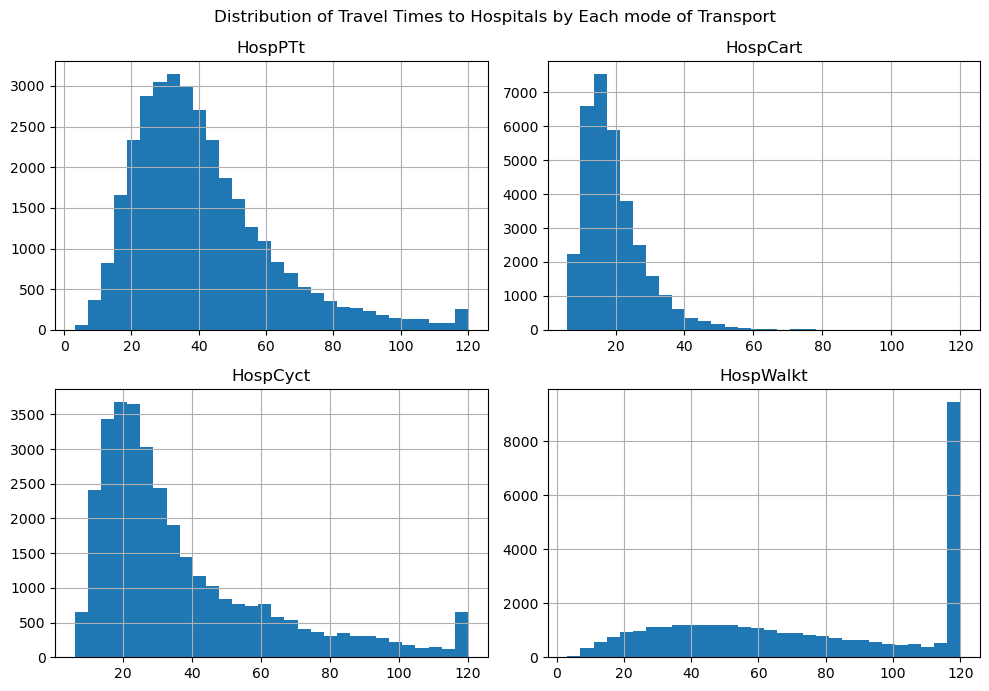

In [7]:
df[["HospPTt", "HospCart", "HospCyct", "HospWalkt"]].hist(
    bins=30,
    figsize=(10, 7)
)

plt.suptitle("Distribution of Travel Times to Hospitals by Each mode of Transport")
plt.tight_layout()
plt.show()

Public Transport (HospPTt): Right-skewed distribution centered around 30-35 minutes, showing that public transit to hospitals typically takes between 20 and 50 minutes.

Car Travel (HospCart): The fastest transport mode by far, with a tight peak around 15-20 minutes and very few locations taking longer than 40 minutes.

Cycling (HospCyct): Moderately fast mode, peaking at 20-25 minutes, though it exhibits a longer right tail compared to cars.

Walking (HospWalkt): The slowest and least practical option, featuring a wide, flat distribution with a massive peak at 120 minutes (the upper data ceiling), indicating that hospitals are completely out of walkable reach for a large portion of areas.

## Public transport travel time by region

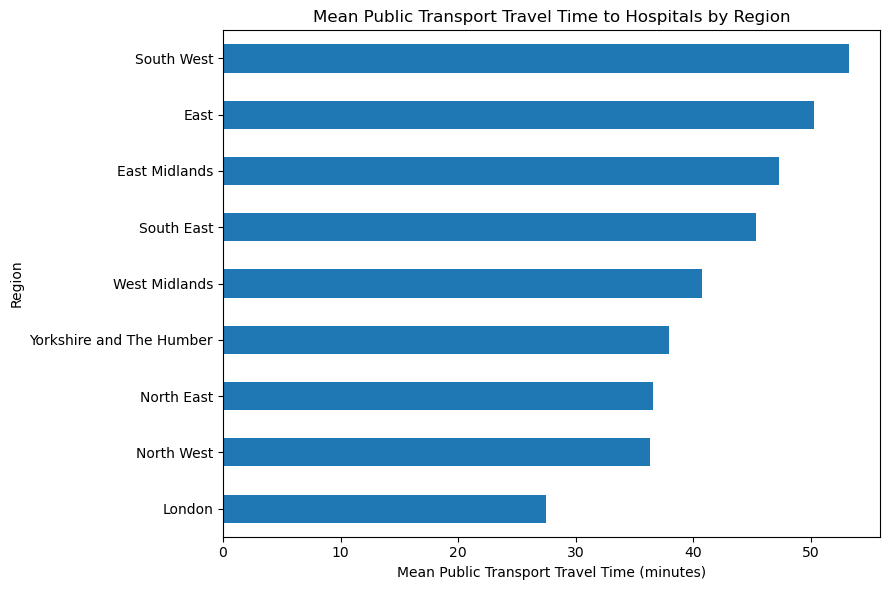

In [8]:
region_pt = (
    df.groupby("Region")["HospPTt"].mean().sort_values()
)

region_pt.plot(
    kind="barh",
    figsize=(9, 6)
)

plt.xlabel("Mean Public Transport Travel Time (minutes)")
plt.ylabel("Region")
plt.title("Mean Public Transport Travel Time to Hospitals by Region")
plt.tight_layout()
plt.show()

Longest Commutes (South West & East): The South West experiences the longest mean public transport travel time to hospitals (~53 minutes), followed closely by the East (~50 minutes) and East Midlands (~47 minutes).

Shortest Commutes (London): London has the shortest average travel time (~27 minutes), benefiting from higher urban density and extensive public transit infrastructure.

Regional Disparity: There is nearly a 2x difference in hospital travel time between London and the South West, highlighting significant rural vs. urban healthcare accessibility gaps across England.

## Public transport accessibility within 30 minutes

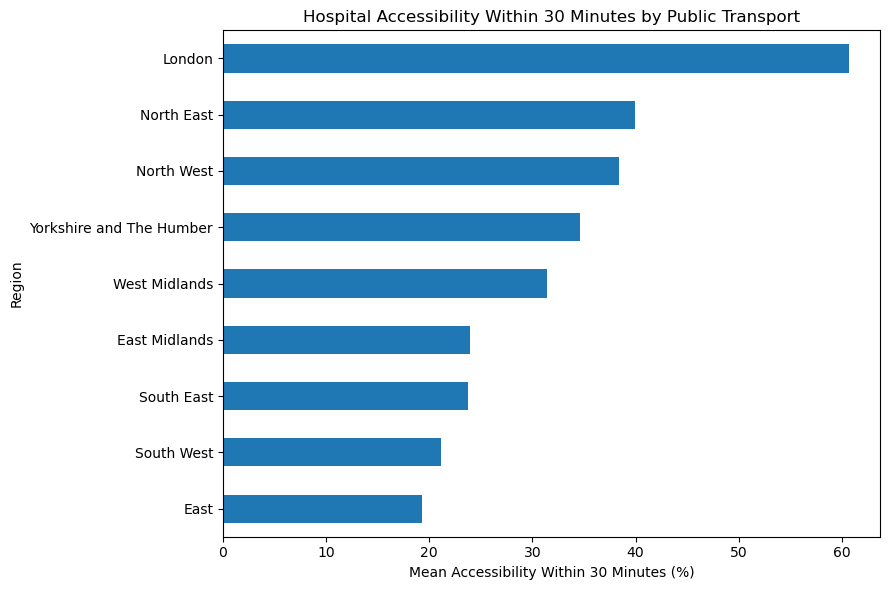

In [9]:
region_pt30 = (
    df.groupby("Region")["HospPT30pct"]
      .mean()
      .sort_values()
)

region_pt30.plot(
    kind="barh",
    figsize=(9, 6)
)

plt.xlabel("Mean Accessibility Within 30 Minutes (%)")
plt.ylabel("Region")
plt.title("Hospital Accessibility Within 30 Minutes by Public Transport")
plt.tight_layout()
plt.show()

London Leads Significantly: Over 60% of areas in London can access a hospital within 30 minutes via public transport, driven by dense transit networks.

Northern Regions Perform Well: The North East and North West follow with strong accessibility rates ranging between 38% and 40%.

Lowest Accessibility in the East: The East region records the lowest percentage at roughly 19%, highlighting stark regional disparities between dense urban centers and more dispersed or rural areas.

## Correlation between selected accessibility variables

In [10]:
corr = df[["HospPTt", "HospCart", "HospCyct", "HospWalkt", "HospPT30pct"]].corr()
display(corr)

,HospPTt,HospCart,HospCyct,HospWalkt,HospPT30pct
HospPTt,1.000000,0.869193,0.871947,0.809951,-0.684360
HospCart,0.869193,1.000000,0.943773,0.816015,-0.616158
HospCyct,0.871947,0.943773,1.000000,0.825774,-0.583997
HospWalkt,0.809951,0.816015,0.825774,1.000000,-0.783513
HospPT30pct,-0.684360,-0.616158,-0.583997,-0.783513,1.000000


# Feature Engineering

## Public transport disadvantage relative to car

In [11]:
df["Hosp_PT_Car_Gap"] = df["HospPTt"] - df["HospCart"]
df["Hosp_PT_Car_Gap"].describe()

count    32844.000000
mean        21.801204
std         13.751736
min         -9.758777
25%         12.469892
50%         19.057024
75%         27.354055
max         99.455941
Name: Hosp_PT_Car_Gap, dtype: float64

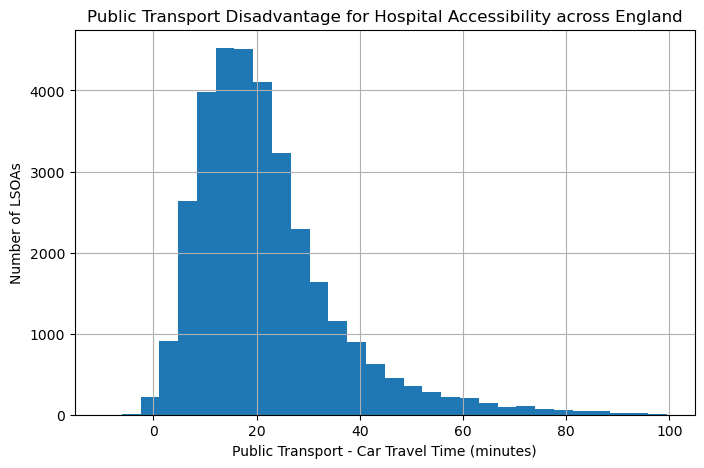

In [12]:
df["Hosp_PT_Car_Gap"].hist(
    bins=30,
    figsize=(8, 5)
)

plt.xlabel("Public Transport - Car Travel Time (minutes)")
plt.ylabel("Number of LSOAs")
plt.title("Public Transport Disadvantage for Hospital Accessibility across England")
plt.show()

The histogram plots the difference between public transport time and car travel time to reach a hospital across England. Peak Disadvantage (15–20 Minutes): The distribution peaks around 15 to 20 additional minutes, showing that taking public transport typically adds about a quarter to a third of an hour to the trip compared to driving. Universal Delay: Nearly the entire distribution lies above zero, highlighting that public transit is almost universally slower than driving for hospital journeys.  A substantial right-sided tail extends up to 60–100 extra minutes, illustrating severe public transit penalties in poorly connected or rural areas where non-car users face significant access barriers.

In [14]:
hospital_features = df[
    [
        "LSOA_code",
        "HospPTt",
        "HospPT30pct",
        "Hosp_PT_Car_Gap",
        "HospCart"
    ]
].copy()

display(hospital_features.head())

,LSOA_code,HospPTt,HospPT30pct,Hosp_PT_Car_Gap,HospCart
0,E01000001,5.174589,100.0,-1.795000,6.969589
1,E01000002,8.865072,100.0,0.699735,8.165337
2,E01000003,7.872362,100.0,-0.596022,8.468384
3,E01000005,16.158480,100.0,6.564989,9.593491
4,E01000006,34.502100,0.0,16.541124,17.960976


The dataset was cleaned and transformed and then the selected features were then saved into a new dataset as shown below

In [15]:
hospital_features.to_excel(
    "hospital_accessibility_features.xlsx",
    index=False
)